Aim: **To implement Image Classification using Convolutional Neural Networks
(CNNs) on the MNIST and CIFAR-10 datasets**.

In [1]:
import cv2
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np

In [2]:
from keras.datasets import mnist

In [3]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

In [4]:
from keras.utils import to_categorical

In [5]:
y_cat_train = to_categorical(y_train,10)

In [6]:
y_cat_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.]], shape=(60000, 10))

In [7]:
y_cat_train.shape

(60000, 10)

In [8]:
y_cat_test = to_categorical(y_test,10)

In [9]:
y_cat_test.shape

(10000, 10)

In [10]:
X_train = X_train.reshape(60000,28,28,1)
X_test = X_test.reshape(10000,28,28,1)

In [11]:
X_train.shape

(60000, 28, 28, 1)

In [12]:
from tensorflow.keras.models import Sequential
from keras.layers import Dense,Conv2D,MaxPool2D,Flatten

In [13]:
model = Sequential(
    [Conv2D(filters=32,kernel_size=(4,4),input_shape = (28,28,1)),
    MaxPool2D(pool_size=(2,2),strides=2),
    Conv2D(filters=64,kernel_size=(4,4),input_shape = (12,12,1)),
    MaxPool2D(pool_size=(2,2),strides=2),
    Flatten(),
    Dense(128,activation="relu"),
    Dense(10,activation="softmax")]
)

c:\Users\ADMIN\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [14]:
model.compile(
    loss = "categorical_crossentropy",
    optimizer = "rmsprop",
    metrics = ["accuracy"]
)

In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 25, 25, 32)     │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 9, 9, 64)       │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 165,866 (647.91 KB)

 Trainable params: 165,866 (647.91 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.fit(X_train,y_cat_train,epochs=2)

Epoch 1/2
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9208 - loss: 0.7794
Epoch 2/2
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9634 - loss: 0.2578


In [17]:
predictions = model.predict(X_test)
predicted_classes = predictions.argmax(axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [18]:
print(predicted_classes[20:50])
print(y_test[20:50])

[9 6 6 5 4 0 7 4 0 1 3 1 3 4 7 2 2 1 2 1 1 7 4 2 3 5 1 2 4 4]
[9 6 6 5 4 0 7 4 0 1 3 1 3 4 7 2 7 1 2 1 1 7 4 2 3 5 1 2 4 4]


In [19]:
from sklearn.metrics import classification_report
print(classification_report(y_test, predicted_classes))

              precision    recall  f1-score   support

           0       0.99      0.96      0.97       980
           1       0.97      0.99      0.98      1135
           2       0.96      0.96      0.96      1032
           3       0.97      0.97      0.97      1010
           4       0.98      0.95      0.97       982
           5       0.95      0.98      0.97       892
           6       0.99      0.96      0.98       958
           7       0.99      0.90      0.94      1028
           8       0.91      0.99      0.94       974
           9       0.94      0.98      0.96      1009

    accuracy                           0.96     10000
   macro avg       0.96      0.96      0.96     10000
weighted avg       0.96      0.96      0.96     10000



In [20]:
confusion_matrix = tf.math.confusion_matrix(labels=y_test, predictions=predicted_classes)
confusion_matrix

<tf.Tensor: shape=(10, 10), dtype=int32, numpy=
array([[ 936,    3,    7,    2,    1,    7,    2,    3,   17,    2],
       [   1, 1122,    0,    2,    0,    1,    3,    0,    6,    0],
       [   1,    1,  989,   10,    7,    2,    1,    2,   18,    1],
       [   0,    0,    6,  980,    1,   11,    0,    0,   10,    2],
       [   2,   10,    1,    0,  936,    0,    2,    1,    2,   28],
       [   0,    1,    2,    5,    0,  875,    1,    0,    5,    3],
       [   4,    1,    1,    2,    6,   13,  921,    0,    9,    1],
       [   1,   18,   27,    6,    2,    4,    0,  927,   25,   18],
       [   0,    0,    0,    1,    1,    3,    0,    0,  962,    7],
       [   1,    3,    2,    3,    3,    2,    1,    2,    8,  984]],
      dtype=int32)>

Text(95.72222222222221, 0.5, 'Actual')

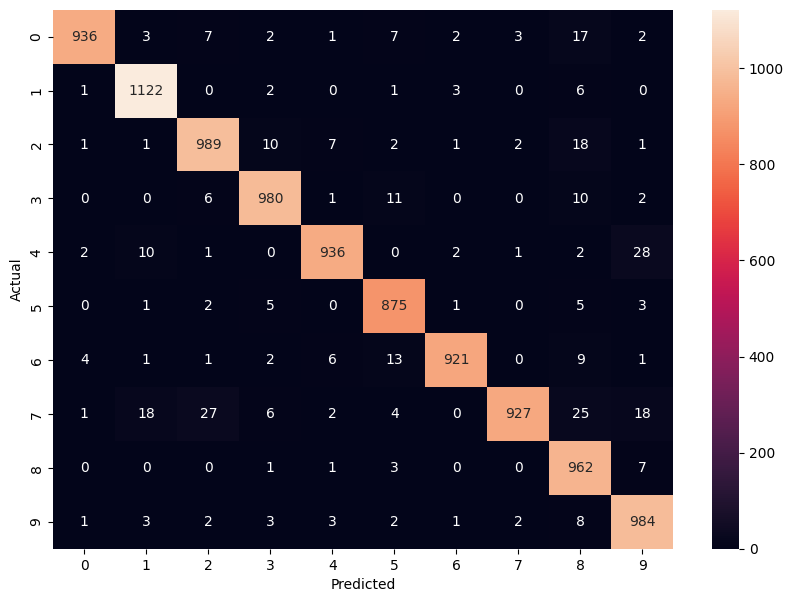

In [21]:
import seaborn as sns

cm=tf.math.confusion_matrix(labels=y_test,predictions=predicted_classes)
plt.figure(figsize=(10,7))
sns.heatmap(cm,annot=True,fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Actual')